# I will use transfer learning for for this project

first I will train a CNN from strach on ESC50 Data and then freeze the parameters and then will train on GENRES_STEMS Data

In [1]:
from golbal_variables import *

In [2]:
import torch, torchaudio, numpy
print(torch.__version__)
print(torchaudio.__version__)
print(numpy.__version__)

2.2.2+cpu
2.2.2+cpu
1.26.4


## Exploring EC50 data

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd

In [4]:
esc50_df = pd.read_csv(ESC_50_MASTER/"meta/esc50.csv")

Files follow a specific pattern: {FOLD}-{CLIP_ID}-{TAKE}-{TARGET}.wav. The TARGET (0-49) is the class ID you are trying to predict.

In [5]:
esc50_df.shape

(2000, 7)

In [6]:
esc50_df.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


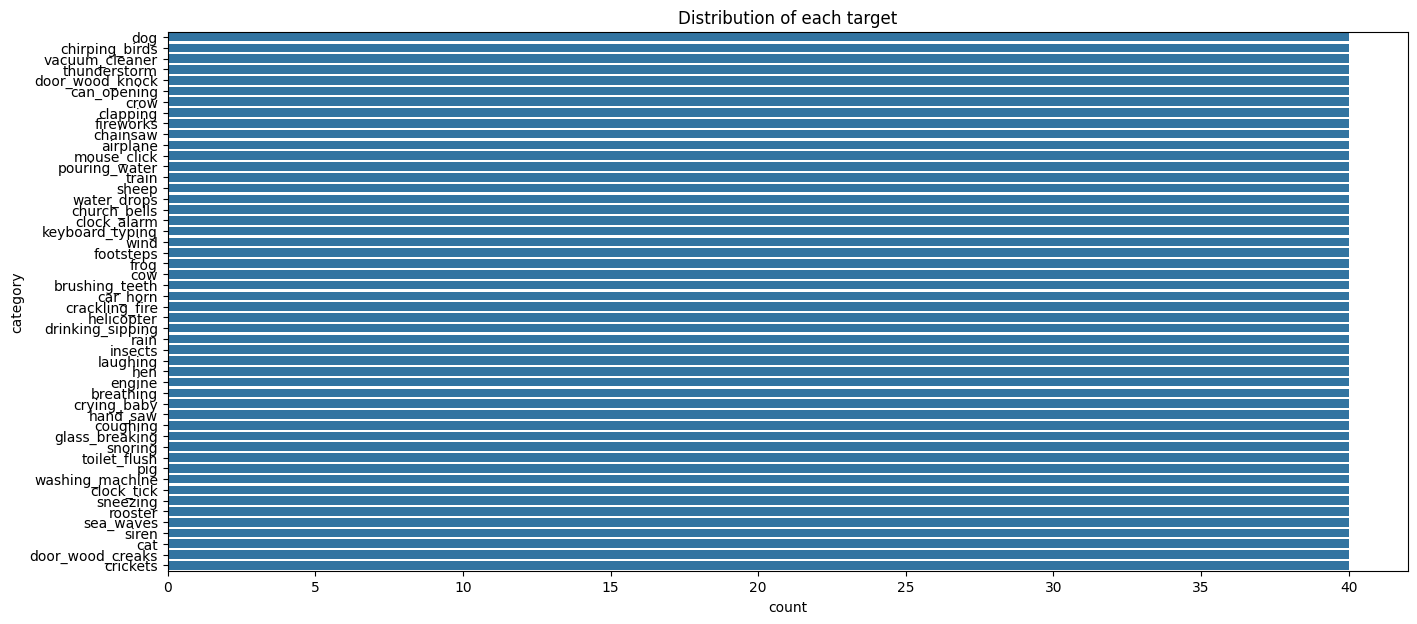

In [7]:
plt.figure(figsize=(16, 7))
sns.countplot(data=esc50_df, y="category")
plt.title("Distribution of each target")
plt.show()

All category have same distribution our data of ECS50 is balanced

## Checking wave forms

### Checking genres

In [27]:
from pathlib import Path
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from IPython.display import display

def plot_each_wav(folder: Path):
    files = list(folder.glob("*.wav")) 
    
    if not files:
        print(f"No .wav files found in {folder}")
        return

    fig, axes = plt.subplots(len(files), 1, figsize=(14, 3 * len(files)), squeeze=False)
    axes = axes.flatten()

    for ax, filename in zip(axes, files):
        data, sample_rate = librosa.load(filename, sr=None)
        librosa.display.waveshow(data, sr=sample_rate, ax=ax)
        
        ax.set_title(filename.name)
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")

    plt.tight_layout()
    plt.show()

    print("\nAudio Samples:\n")
    for filename in files:
        print(filename.name)
        display(ipd.Audio(str(filename)))
        print("-" * 60)

### BLUES

In [ ]:
# plot_each_wav(BLUES / "blues.00000")

### classical

In [ ]:
# plot_each_wav(CLASSICAL / "classical.00000")

## 

# Now let's train a model on ESC50 dataset

In [8]:
from helper.custom_dataloader import ESC50_DataLoader
from torch.utils.data import DataLoader

dataset = ESC50_DataLoader(ESC_50_MASTER)
dataset.load_meta_data(ESC_50_MASTER/"meta/esc50.csv")

loader = DataLoader(dataset, batch_size=16, shuffle=True)

for x, y in loader:
    print(x.shape)
    print(y.shape)
    break

Loading metadata from file: data\ESC-50-master\meta\esc50.csv
torch.Size([16, 1, 256, 216])
torch.Size([16])


Checking if loader if giving correct spectrum

In [4]:
import matplotlib.pyplot as plt
import librosa
import librosa.display

Batch shape: torch.Size([16, 1, 256, 216])
Labels shape: torch.Size([16])


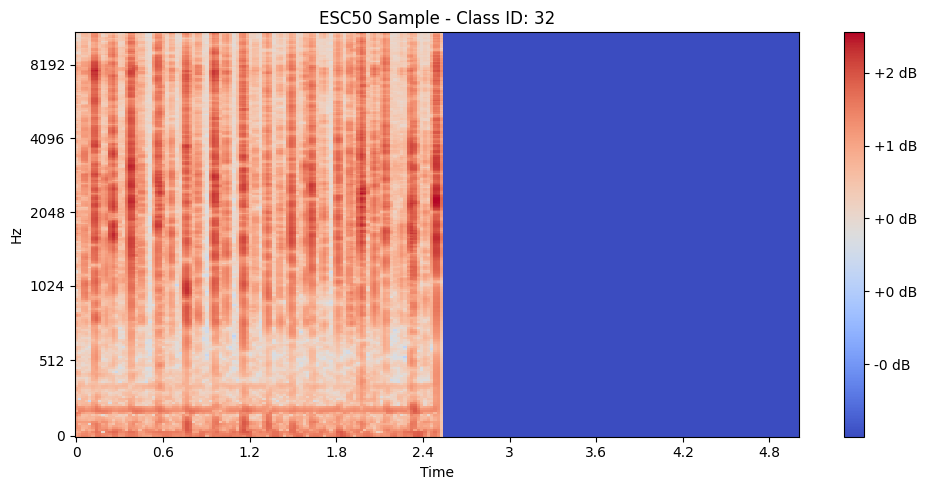

In [9]:
mel_batch, label_batch = next(iter(loader))

print("Batch shape:", mel_batch.shape)
print("Labels shape:", label_batch.shape)

# take FIRST sample from batch
mel = mel_batch[0]       # (1,256,216)
label = label_batch[0]   # single label

# remove channel dimension
mel = mel[0]             # (256,216)

# convert to numpy
mel = mel.detach().cpu().numpy()

plt.figure(figsize=(10,5))

librosa.display.specshow(
    mel,
    sr=22050,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title(f"ESC50 Sample - Class ID: {label.item()}")
plt.tight_layout()
plt.show()

In [2]:
from helper.custom_dataloader import GenreDataLoader
from torch.utils.data import DataLoader

dataset = GenreDataLoader(GENRES_STEMS)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for x, y in loader:
    print(x.shape)
    print(y.shape)
    break

Classes: {'blues': 0, 'classical': 1, 'country': 2, 'disco': 3, 'hiphop': 4, 'jazz': 5, 'metal': 6, 'pop': 7, 'reggae': 8, 'rock': 9}
Total songs: 1000
torch.Size([16, 1, 256, 216])
torch.Size([16])


Batch shape: torch.Size([16, 1, 256, 216])
Labels shape: torch.Size([16])


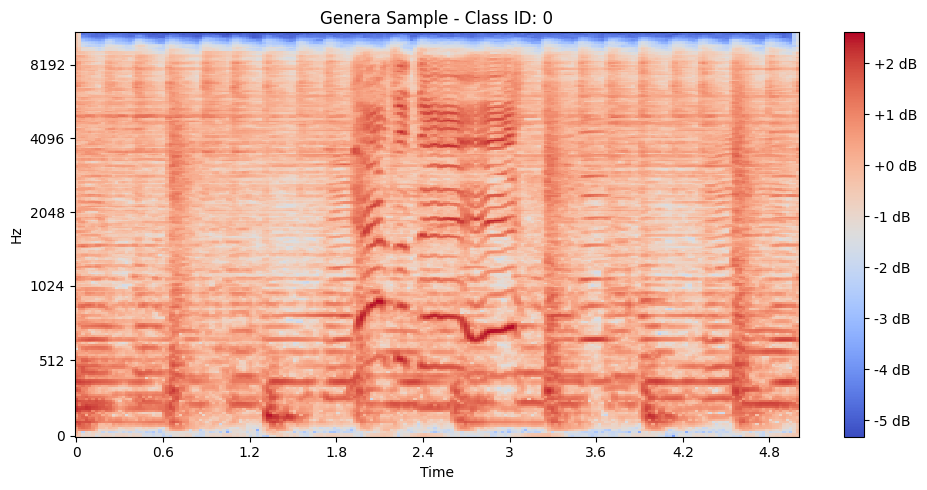

In [6]:
mel_batch, label_batch = next(iter(loader))

print("Batch shape:", mel_batch.shape)
print("Labels shape:", label_batch.shape)

# take FIRST sample from batch
mel = mel_batch[0]       # (1,256,216)
label = label_batch[0]   # single label

# remove channel dimension
mel = mel[0]             # (256,216)

# convert to numpy
mel = mel.detach().cpu().numpy()

plt.figure(figsize=(10,5))

librosa.display.specshow(
    mel,
    sr=22050,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title(f"Genera Sample - Class ID: {label.item()}")
plt.tight_layout()
plt.show()